# | Inventory Replenishment Agent | By Jaden Dang, Kenny Le, Sumair Dawani, Sean Hensley, Alexander Ching 2026

A small, transparent agent that decides **every day, for every SKU, whether to order or wait**, then
simulates the outcome and compares it with a simple fixed-rule baseline.

**How to run:** *Kernel → Restart & Run All*. Needs only `numpy`, `pandas`, `matplotlib`.
The three CSVs (`sales.csv`, `inventory.csv`, `params.csv`) are read from the notebook's folder; if they are
missing, the notebook auto-generates them (seeded, so results are reproducible).

**Contents:** 1 Design Document · 2 Data · 3 Forecasting · 4 Safety stock & agent · 5 Simulation & daily log ·
6 Evaluation vs baseline · 7 Trade-offs · 8 Scaling note

## 1. Design Document

**Goal.** Each day a planner must decide whether to reorder each SKU. Order late and customers meet empty shelves; order early or too much and cash is tied up in stock that costs money to hold. The agent makes this call per SKU per day to **minimize stockouts and total cost (holding + stockout + ordering)** while meeting each SKU's target service level.

| | |
|---|---|
| **Inputs** (per SKU, per day) | EWMA demand forecast and recent forecast error · on-hand stock · POs in transit · lead time · service level · `min_order_qty` · cost parameters |
| **Outputs** (per SKU, per day) | **ORDER *q* units** (arrives after the lead time) **or WAIT**, with a plain-English rationale in the daily log |

**Decision rule.** (1) Forecast daily demand *f* with an EWMA. (2) Safety stock *SS = z(service level) × σ(forecast error) × √(L+R)*, with *L* = lead time and *R* = review period (1 day). (3) Project on-hand stock day by day over *L+R* days, counting POs in transit. (4) If projected stock at the end falls below *SS* → **ORDER** up to *f × (L+R+order cycle) + SS*; otherwise **WAIT** to avoid holding cost.

**Guardrails**
- **`min_order_qty`:** never order less.
- **Lead time:** the projection covers *L+R* days and counts in-transit POs (no double ordering).
- **Service level:** safety stock uses the SKU's z-score and its measured forecast error.
- **No over-ordering:** order only when the projection breaches *SS*, and only up to a target; demand spikes are clipped (mean + 3σ) before they update the forecast; position is capped at 21 days of typical demand (trailing 28-day mean) + *SS*; no orders that cannot arrive before the horizon ends.
- **Holding vs stockout:** a unit of safety stock costs `holding_cost_per_day` every day; a missing unit costs `stockout_cost`. The service level is the dial between them (Section 7 prices it).

**Metrics.** *Stockout* = a day when demand exceeds stock (units short also counted). *Fill rate* = units sold ÷ units demanded. *Total cost* = holding (end-of-day stock × cost/day) + stockout (units short × cost) + ordering (fixed cost × POs).

**Ethics & trust.** A stockout is a broken promise to a customer, so the agent protects service reliability; buying "just in case" wastes working capital, so it also owns cost responsibility. Both are measured. Every decision is written to a **daily log** with its inputs and reason, so a human can audit or override any order.

**Assumptions.** Unmet demand is lost (no backorders); sales ≈ true demand; SKUs are independent; deliveries arrive exactly on the lead time; fixed cost per PO (default 10).

In [1]:
import os; print(os.getcwd()); print(os.listdir())

/content
['.config', 'sales.csv', '.ipynb_checkpoints', 'params.csv', 'inventory.csv', 'sample_data']


In [2]:
# 2.0  Setup: imports and ONE place for every adjustable parameter

import math
from collections import deque
from dataclasses import dataclass, replace
from pathlib import Path
from statistics import NormalDist
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:                                    # `display` exists in Jupyter; fall back to print in a plain script
    from IPython.display import display
except ImportError:
    display = print


@dataclass(frozen=True)
class Config:
    """All tunable settings. Use dataclasses.replace(cfg, alpha=0.5) to try a variant."""
    #  forecasting
    alpha: float = 0.20                  # EWMA smoothing (0<alpha<=1). alpha=1.0 is the naive "yesterday = today" forecast
    warmup_days: int = 14                # first N days of sales.csv only initialise the forecast & error stats
    error_window: int = 28               # recent one-day forecast errors used for safety stock
    spike_clip_sigmas: Optional[float] = 3.0   # a one-off demand spike updates the forecast by at most mean + k*sigma (None = off)
    #  ordering policy
    review_period_days: int = 1          # the agent reviews every day
    order_cycle_days: int = 7            # days of demand an order should cover beyond the protection window
    max_cover_days: int = 21             # inventory cap: position <= max_cover_days x typical demand (trailing mean) + safety stock
                                         # (must be >= lead time + review period + order_cycle_days; the agent checks this)
    service_level_override: Optional[float] = None   # replace params.csv service_level for ALL SKUs (None = use file)
    lead_time_override: Optional[int] = None         # replace params.csv lead_time_days for ALL SKUs (None = use file)
    #  costs
    order_cost_per_po: float = 10.0      # fixed cost per purchase order (0 = ignore ordering cost)
    #  baseline (fixed reorder rule)
    baseline_buffer_days: int = 3        # baseline reorder point = avg demand x (lead time + buffer_days)
    #  run
    seed: int = 42                       # only used when the CSVs have to be auto-generated
    data_dir: str = "."                  # folder holding sales.csv / inventory.csv / params.csv

    def __post_init__(self):
        if not 0 < self.alpha <= 1:
            raise ValueError("alpha must be in (0, 1]")
        if self.warmup_days < 7:
            raise ValueError("warmup_days must be >= 7 so the forecast and error stats have some history")
        if self.review_period_days < 1:
            raise ValueError("review_period_days must be >= 1")


CFG = Config()      # <- change parameters here (e.g. Config(alpha=0.5, service_level_override=0.98))
print(CFG)

Config(alpha=0.2, warmup_days=14, error_window=28, spike_clip_sigmas=3.0, review_period_days=1, order_cycle_days=7, max_cover_days=21, service_level_override=None, lead_time_override=None, order_cost_per_po=10.0, baseline_buffer_days=3, seed=42, data_dir='.')


## 2. Data: load, validate, aggregate

`sales.csv` is a transaction log (several rows per SKU per day are possible), so demand is **aggregated per SKU per day**.
Days with no rows mean "nothing sold" and become zero-demand days.

In [3]:

# 2.1  Synthetic data generator (used only if the CSV files are missing)

_WEEKLY = np.array([0.90, 0.90, 0.95, 1.00, 1.15, 1.25, 0.85])      # Mon..Sun pattern, averages to 1.0

# base = mean units/day; noise = lognormal sigma; trend = growth per day;
# promos = (first_day, last_day, multiplier); shift = (day, multiplier) level change; lumpy = occasional bulk orders
_DEMAND_PROFILES = {
    "SKU_A": dict(base=40, noise=0.15, trend=0.002, promos=[(38, 41, 1.6)], shift=None, lumpy=False),
    "SKU_B": dict(base=18, noise=0.30, trend=0.000, promos=[(25, 27, 2.0), (66, 68, 1.8)], shift=(55, 1.25), lumpy=False),
    "SKU_C": dict(base=4,  noise=0.50, trend=0.000, promos=[], shift=None, lumpy=True),
}

# Illustrative cost inputs. stockout_cost / holding_cost is ~150 for A and B (and ~70 for C), which is the ratio at which a
# ~95% (and ~90%) service level is economically sensible for a 7-day order cycle: service* ~= 1 - cycle_days * holding / stockout.
_DEFAULT_PARAMS = pd.DataFrame({
    "sku": ["SKU_A", "SKU_B", "SKU_C"],
    "unit_cost": [5.00, 12.00, 40.00],
    "holding_cost_per_day": [0.010, 0.030, 0.120],
    "stockout_cost": [1.50, 4.50, 8.40],
    "lead_time_days": [3, 5, 7],
    "min_order_qty": [100, 60, 20],
    "service_level": [0.95, 0.95, 0.90],
})
_DEFAULT_INVENTORY = pd.DataFrame({"sku": ["SKU_A", "SKU_B", "SKU_C"], "opening_stock": [250, 140, 45]})


def _split_into_lines(rng, qty):
    """Split one day's total into 1-3 transaction lines (so aggregation is a real step)."""
    if qty == 0:
        return []
    k = int(rng.integers(1, min(qty, 3) + 1))
    if k == 1:
        return [qty]
    cuts = np.sort(rng.choice(np.arange(1, qty), size=k - 1, replace=False))
    return np.diff(np.concatenate([[0], cuts, [qty]])).tolist()


def generate_data(data_dir=".", n_days=90, start="2026-06-01", seed=42, write=True):
    """Create sales / inventory / params tables (and write the three CSVs when write=True)."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range(start, periods=n_days, freq="D")
    rows = []
    for sku, prof in _DEMAND_PROFILES.items():
        for t, date in enumerate(dates):
            mu = prof["base"] * _WEEKLY[date.dayofweek] * (1 + prof["trend"] * t)
            for first, last, mult in prof["promos"]:
                if first <= t <= last:
                    mu *= mult
            if prof["shift"] and t >= prof["shift"][0]:
                mu *= prof["shift"][1]
            if prof["lumpy"] and rng.random() < 0.08:
                mu *= 4
            qty = int(rng.poisson(mu * rng.lognormal(-prof["noise"] ** 2 / 2, prof["noise"])))
            rows += [(date.strftime("%Y-%m-%d"), sku, line) for line in _split_into_lines(rng, qty)]
    sales = (pd.DataFrame(rows, columns=["date", "sku", "qty_sold"])
               .sort_values(["date", "sku"], kind="stable").reset_index(drop=True))
    inventory, params = _DEFAULT_INVENTORY.copy(), _DEFAULT_PARAMS.copy()
    if write:
        folder = Path(data_dir)
        folder.mkdir(parents=True, exist_ok=True)
        sales.to_csv(folder / "sales.csv", index=False)
        inventory.to_csv(folder / "inventory.csv", index=False)
        params.to_csv(folder / "params.csv", index=False)
    sales["date"] = pd.to_datetime(sales["date"])
    return sales, inventory, params



# 2.2  Load, validate, aggregate

_REQUIRED_COLUMNS = {
    "sales": ["date", "sku", "qty_sold"],
    "inventory": ["sku", "opening_stock"],
    "params": ["sku", "unit_cost", "holding_cost_per_day", "stockout_cost",
               "lead_time_days", "min_order_qty", "service_level"],
}


def validate_data(sales, inventory, params):
    """Fail early with a clear message if the inputs are unusable; repair what is safely repairable."""
    for name, df in (("sales", sales), ("inventory", inventory), ("params", params)):
        missing = set(_REQUIRED_COLUMNS[name]) - set(df.columns)
        if missing:
            raise ValueError(f"{name}.csv is missing columns: {sorted(missing)}")
    if sales["qty_sold"].isna().any() or (sales["qty_sold"] < 0).any():
        print("WARNING: blank/negative qty_sold values found in sales.csv - treated as 0.")
        sales = sales.assign(qty_sold=sales["qty_sold"].fillna(0).clip(lower=0))
    if not params["sku"].is_unique or not inventory["sku"].is_unique:
        raise ValueError("params.csv and inventory.csv must have one row per SKU")
    if set(params["sku"]) != set(inventory["sku"]):
        raise ValueError("params.csv and inventory.csv must list the same SKUs")
    unknown = set(sales["sku"]) - set(params["sku"])
    if unknown:
        raise ValueError(f"sales.csv contains SKUs that are not in params.csv: {sorted(unknown)}")
    if (params["lead_time_days"] < 1).any() or (params["min_order_qty"] < 1).any():
        raise ValueError("lead_time_days and min_order_qty must be >= 1")
    if not params["service_level"].between(0.50, 0.999).all():
        raise ValueError("service_level must be between 0.50 and 0.999")
    return sales, inventory, params


def load_data(cfg):
    """Read the three CSVs (auto-generating them if absent) and validate them."""
    folder = Path(cfg.data_dir)
    files = {name: folder / f"{name}.csv" for name in ("sales", "inventory", "params")}
    absent = [f.name for f in files.values() if not f.exists()]
    if absent:
        print(f"Missing {absent} in '{folder.resolve()}' -> auto-generating a synthetic dataset (seed={cfg.seed}).")
        generate_data(cfg.data_dir, seed=cfg.seed, write=True)
    sales = pd.read_csv(files["sales"], parse_dates=["date"])
    inventory = pd.read_csv(files["inventory"])
    params = pd.read_csv(files["params"])
    return validate_data(sales, inventory, params)


def aggregate_daily_demand(sales, skus):
    """Sum transaction lines to one demand number per SKU per calendar day (rows = dates, columns = SKUs)."""
    daily = sales.groupby(["date", "sku"])["qty_sold"].sum().unstack("sku")
    calendar = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
    daily = daily.reindex(index=calendar, columns=skus).fillna(0).astype(int)   # no rows = nothing sold = 0
    daily.index.name = "date"
    return daily


def build_inputs(sales, inventory, params_df, cfg):
    """Turn raw tables into (daily demand, per-SKU parameter dicts, opening stock), applying any config overrides."""
    daily = aggregate_daily_demand(sales, list(params_df["sku"]))
    params = {sku: {k: (v.item() if hasattr(v, "item") else v) for k, v in row.items()}
              for sku, row in params_df.set_index("sku").to_dict("index").items()}
    for p in params.values():
        if cfg.lead_time_override is not None:
            p["lead_time_days"] = int(cfg.lead_time_override)       # adjustable lead time
        if cfg.service_level_override is not None:
            p["service_level"] = float(cfg.service_level_override)  # adjustable service level
        p["lead_time_days"] = int(p["lead_time_days"])
        p["min_order_qty"] = int(p["min_order_qty"])
    opening = {sku: int(q) for sku, q in inventory.set_index("sku")["opening_stock"].items()}
    if len(daily) - cfg.warmup_days < 10:
        raise ValueError("Need at least 10 days after the warm-up period to simulate.")
    return daily, params, opening

In [4]:
RAW = load_data(CFG)                                   # (sales, inventory, params) as validated DataFrames
sales_raw, inventory_raw, params_raw = RAW
daily_demand, PARAMS, OPENING = build_inputs(*RAW, CFG)

print(f"sales.csv: {len(sales_raw)} transaction rows | inventory.csv: {len(inventory_raw)} SKUs | params.csv: {len(params_raw)} SKUs")
print(f"Aggregated to {len(daily_demand)} days x {daily_demand.shape[1]} SKUs "
      f"({daily_demand.index.min():%Y-%m-%d} to {daily_demand.index.max():%Y-%m-%d}); "
      f"first {CFG.warmup_days} days = warm-up, remaining {len(daily_demand) - CFG.warmup_days} days = simulation horizon.\n")
print("sales.csv (raw transactions):");  display(sales_raw.head(6))
print("Daily demand per SKU after aggregation (head):");  display(daily_demand.head(6))
print("Mean / std of daily demand:");  display(daily_demand.agg(["mean", "std"]).round(1))
print("params.csv:");  display(params_raw)
print("inventory.csv:");  display(inventory_raw)

sales.csv: 515 transaction rows | inventory.csv: 3 SKUs | params.csv: 3 SKUs
Aggregated to 90 days x 3 SKUs (2026-06-01 to 2026-08-29); first 14 days = warm-up, remaining 76 days = simulation horizon.

sales.csv (raw transactions):


,date,sku,qty_sold
0,2026-06-01,SKU_A,36
1,2026-06-01,SKU_B,1
2,2026-06-01,SKU_B,2
3,2026-06-01,SKU_B,7
4,2026-06-01,SKU_C,5
5,2026-06-02,SKU_A,14


Daily demand per SKU after aggregation (head):


sku,SKU_A,SKU_B,SKU_C
date,,,
2026-06-01,36,10,5
2026-06-02,31,18,6
2026-06-03,45,7,1
2026-06-04,36,9,3
2026-06-05,51,34,3
2026-06-06,40,36,7


Mean / std of daily demand:


sku,SKU_A,SKU_B,SKU_C
mean,45.2,21.0,5.5
std,13.5,11.0,6.7


params.csv:


,sku,unit_cost,holding_cost_per_day,stockout_cost,lead_time_days,min_order_qty,service_level
0,SKU_A,5.0,0.01,1.5,3,100,0.95
1,SKU_B,12.0,0.03,4.5,5,60,0.95
2,SKU_C,40.0,0.12,8.4,7,20,0.90


inventory.csv:


,sku,opening_stock
0,SKU_A,250
1,SKU_B,140
2,SKU_C,45


## 3. Forecasting: EWMA with daily updates

Forecast for tomorrow: **f(t+1) = α·d(t) + (1−α)·f(t)**. It is updated every day after demand is observed.
`α = 1` gives the naive "yesterday = today" forecast. The one-day-ahead **forecast error** *e(t) = d(t) − f(t)* is stored in a rolling
window; its root-mean-square drives the safety stock (so a noisier SKU automatically gets more buffer).

In [5]:
class EWMAForecaster:
    """EWMA demand forecast plus a rolling record of its own one-day-ahead errors.

    Over-ordering guardrail: when `clip_sigmas` is set, a demand spike can raise the forecast by at most
    (forecast + clip_sigmas x recent error sigma), so a single bulk order does not trigger a huge replenishment.
    The raw (unclipped) error is still recorded, so the safety stock keeps seeing the real risk."""

    def __init__(self, alpha, initial_level, error_window=28, clip_sigmas=None):
        self.alpha = alpha
        self.level = float(initial_level)          # = forecast for the next day
        self.errors = deque(maxlen=error_window)   # recent e(t) = actual - forecast used
        self.clip_sigmas = clip_sigmas

    def forecast(self):
        return self.level

    def update(self, actual):
        """Call once per day after demand is known: record the error, then move the forecast."""
        sigma_before = self.error_rmse() if len(self.errors) >= 7 else None
        error = actual - self.level
        self.errors.append(error)
        value = actual
        if self.clip_sigmas is not None and sigma_before is not None:
            value = min(actual, self.level + self.clip_sigmas * sigma_before)   # damp one-off spikes
        self.level = self.alpha * value + (1 - self.alpha) * self.level
        return error

    def error_rmse(self):
        """Root-mean-square of recent forecast errors (includes bias, so it is a conservative sigma)."""
        if not self.errors:
            return 0.0
        return math.sqrt(sum(e * e for e in self.errors) / len(self.errors))


def build_forecaster(history, alpha, error_window, clip_sigmas=None):
    """Initialise on the warm-up history: start at the first week's mean, then roll through every warm-up day."""
    values = np.asarray(history, dtype=float)
    fc = EWMAForecaster(alpha, initial_level=values[:7].mean(), error_window=error_window, clip_sigmas=clip_sigmas)
    for x in values:
        fc.update(x)
    return fc


def forecast_accuracy(daily, warmup, error_window, clip_sigmas, alphas=(1.0, 0.1, 0.2, 0.3, 0.5)):
    """RMSE of one-day-ahead forecasts over the simulation horizon, for several alphas (alpha=1.0 is plain naive)."""
    out = {}
    for sku in daily.columns:
        series = daily[sku].to_numpy(dtype=float)
        row = {}
        for a in alphas:
            fc = build_forecaster(series[:warmup], a, error_window, None if a == 1.0 else clip_sigmas)
            errs = [fc.update(x) for x in series[warmup:]]
            row["naive (alpha=1.0)" if a == 1.0 else f"EWMA alpha={a}"] = math.sqrt(np.mean(np.square(errs)))
        out[sku] = row
    return pd.DataFrame(out).T.round(2)


print("One-day-ahead forecast RMSE on the simulation horizon (lower is better):")
display(forecast_accuracy(daily_demand, CFG.warmup_days, CFG.error_window, CFG.spike_clip_sigmas))

One-day-ahead forecast RMSE on the simulation horizon (lower is better):


,naive (alpha=1.0),EWMA alpha=0.1,EWMA alpha=0.2,EWMA alpha=0.3,EWMA alpha=0.5
SKU_A,19.14,14.33,14.54,14.89,15.71
SKU_B,11.32,11.28,11.39,11.46,11.49
SKU_C,10.02,7.30,7.40,7.51,7.78


## 4. Safety stock, inventory projection and the agent

* **Safety stock:** `SS = z(service_level) × σ_error × √(L+R)`.
* **Projection:** starting from today's on-hand stock, subtract forecast demand each day and add POs on the day they arrive, for
  the next *L+R* days (the *protection window*: an order placed today lands in *L* days and must last until the next order could land).
* **Rule:** projected on-hand at the end of the window `< SS` → order; else wait.
* **Quantity:** order up to `f × (L+R+order_cycle) + SS`, but never below `min_order_qty` and never above the inventory cap.

In [6]:
def z_score(service_level):
    """Standard-normal z for a cycle service level, e.g. 0.95 -> 1.645."""
    return NormalDist().inv_cdf(service_level)


def safety_stock(sigma_daily, service_level, protection_days):
    """Buffer that covers forecast error over the protection window at the target service level."""
    return z_score(service_level) * sigma_daily * math.sqrt(protection_days)


def project_inventory(on_hand, pipeline, daily_forecast, horizon_days, today):
    """Projected END-of-day on-hand for days today .. today+horizon_days-1 if NO new order is placed.
    `on_hand` already includes anything received today; `pipeline` is a list of (arrival_day, qty).
    Values are not floored at 0, so a negative number is the projected shortfall in units."""
    projected, stock = [], on_hand
    for k in range(horizon_days):
        if k > 0:
            stock += sum(q for arrival, q in pipeline if arrival == today + k)   # receipts at the start of the day
        stock -= daily_forecast                                                   # expected demand that day
        projected.append(stock)
    return projected


@dataclass(frozen=True)
class Decision:
    """One day's decision for one SKU, with the numbers behind it (this becomes one row of the daily log)."""
    qty: int
    reason: str
    forecast: float = float("nan")
    sigma: float = float("nan")
    safety_stock: float = float("nan")
    reorder_point: float = float("nan")
    inv_position: float = float("nan")
    proj_end: float = float("nan")
    order_up_to: float = float("nan")
    ip_cap: float = float("nan")

    @property
    def action(self):
        return "ORDER" if self.qty > 0 else "WAIT"

    def as_wait(self, reason):
        return replace(self, qty=0, reason=reason)


class ReplenishmentAgent:
    """Forecast-driven agent: EWMA forecast + error-based safety stock + lead-time inventory projection."""

    def __init__(self, sku, p, history, cfg):
        self.sku, self.p, self.cfg = sku, p, cfg
        self.L = p["lead_time_days"]
        self.H = self.L + cfg.review_period_days                       # protection window = lead time + review period
        if cfg.max_cover_days < self.H + cfg.order_cycle_days:
            raise ValueError(f"max_cover_days ({cfg.max_cover_days}) must be >= lead time + review period + order cycle "
                             f"({self.H + cfg.order_cycle_days}) for {sku}")
        self.forecaster = build_forecaster(history, cfg.alpha, cfg.error_window, cfg.spike_clip_sigmas)
        self.recent_demand = deque(history, maxlen=cfg.error_window)    # trailing demand = "typical" level for the cap

    def decide(self, day, on_hand, pipeline):
        p, cfg, H, L = self.p, self.cfg, self.H, self.L
        f = self.forecaster.forecast()                                 # expected units per day
        sigma = self.forecaster.error_rmse()                           # typical one-day forecast error
        ss = safety_stock(sigma, p["service_level"], H)                # buffer for forecast error over the window
        in_transit = sum(q for _, q in pipeline)
        position = on_hand + in_transit                                # inventory position = on hand + on order
        projected = project_inventory(on_hand, pipeline, f, H, day)    # day-by-day projection, no new order
        proj_end = projected[-1]                                       # (= position - f*H, as all POs land inside the window)
        reorder_point = f * H + ss
        typical = sum(self.recent_demand) / len(self.recent_demand)    # trailing mean: does not chase one-off spikes
        cap = typical * cfg.max_cover_days + ss                        # guardrail: never hold more than ~3 weeks of typical demand
        uncapped = f * (H + cfg.order_cycle_days) + ss
        order_up_to = min(uncapped, cap)
        facts = dict(forecast=f, sigma=sigma, safety_stock=ss, reorder_point=reorder_point,
                     inv_position=position, proj_end=proj_end, order_up_to=order_up_to, ip_cap=cap)

        if proj_end >= ss:                                             # projection stays above the buffer -> wait
            return Decision(0, f"covered: projected stock {round(proj_end)} >= SS {round(ss)} after {H}d; waiting saves holding cost", **facts)

        needed = math.ceil(order_up_to - position)                     # units to reach the order-up-to level
        if position + needed > cap:                                    # rounding up must not push us over the cap
            needed = math.floor(cap - position)
        qty = max(needed, p["min_order_qty"])                          # guardrail: respect the minimum order quantity
        notes = " [trimmed to inventory cap]" if uncapped > cap else ""
        if qty > needed:
            notes += " [raised to MOQ]"
        if position + qty > cap:                                       # MOQ would breach the inventory cap
            if proj_end >= 0:
                return Decision(0, f"MOQ {p['min_order_qty']} would lift position above cap {round(cap)} and no stockout is projected; waiting", **facts)
            notes += " [cap exceeded to avoid stockout]"
        if L > 0 and min(projected[:L]) < 0:                           # shortfall before this order can possibly arrive
            notes += " [WARNING: shortfall projected before delivery]"
        return Decision(qty, f"projected stock {round(proj_end)} < SS {round(ss)} after {H}d -> order up to {round(order_up_to)}{notes}", **facts)

    def observe(self, demand):
        self.forecaster.update(demand)                                 # forecast updates every day
        self.recent_demand.append(demand)                              # trailing window for the inventory cap


class FixedReorderPointBaseline:
    """Baseline: static (s, Q) rule. No forecast updates, no error-based safety stock, no projection.
    Reorder point = average warm-up demand x (lead time + buffer_days); order quantity = average demand x order cycle (>= MOQ)."""

    def __init__(self, sku, p, history, cfg):
        self.p = p
        avg = float(np.mean(history))
        self.avg = avg
        self.reorder_point = avg * (p["lead_time_days"] + cfg.baseline_buffer_days)
        self.order_qty = max(p["min_order_qty"], math.ceil(avg * cfg.order_cycle_days))

    def decide(self, day, on_hand, pipeline):
        position = on_hand + sum(q for _, q in pipeline)
        facts = dict(forecast=self.avg, sigma=0.0, safety_stock=self.reorder_point - self.avg * self.p["lead_time_days"],
                     reorder_point=self.reorder_point, inv_position=position)
        if position <= self.reorder_point:
            return Decision(self.order_qty, f"position {round(position)} <= fixed reorder point {round(self.reorder_point)} -> order fixed Q", **facts)
        return Decision(0, f"position {round(position)} > fixed reorder point {round(self.reorder_point)}", **facts)

    def observe(self, demand):
        pass                                                           # static rule: never learns

## 5. Simulation and daily agent log

Each simulated day, for each SKU, in this order:
1. **Receive** any PO due today → 2. **Agent decides** (order or wait) using only information up to yesterday →
3. **Demand happens** (sales = min(stock, demand); the rest is lost) → 4. **Costs** are booked (holding on end-of-day stock, stockout on units lost, fixed cost per PO) →
5. **Forecast updates** with today's demand.

An order placed on day *t* arrives on day *t + lead time*. The same simulator runs both the agent and the baseline, so the comparison is like-for-like.

In [7]:
def simulate(daily, params, opening, policy_factory, cfg, policy_name):
    """Day-by-day simulation of one policy over all SKUs. Returns the full daily log as a DataFrame."""
    records = []
    for sku, p in params.items():
        series = daily[sku]
        history, horizon = series.iloc[:cfg.warmup_days], series.iloc[cfg.warmup_days:]
        policy = policy_factory(sku, p, history, cfg)
        lead, last_day = p["lead_time_days"], len(horizon) - 1
        on_hand, pipeline = int(opening[sku]), []                       # pipeline = [(arrival_day, qty), ...]

        for day, (date, demand) in enumerate(horizon.items()):
            # 1) receive purchase orders that are due today
            received = sum(q for arrival, q in pipeline if arrival == day)
            pipeline = [(a, q) for a, q in pipeline if a != day]
            on_hand += received
            in_transit = sum(q for _, q in pipeline)

            # 2) the policy decides (order or wait)
            decision = policy.decide(day, on_hand, pipeline)
            if decision.qty > 0 and day + lead > last_day:               # evaluation guardrail: skip POs that could never arrive
                decision = decision.as_wait("order would arrive after the last simulated day")
            if decision.qty > 0:
                pipeline.append((day + lead, decision.qty))

            # 3) demand is served from stock; unmet demand is lost
            demand = int(demand)
            sold = min(on_hand, demand)
            lost = demand - sold
            on_hand -= sold

            # 4) book costs
            records.append(dict(
                policy=policy_name, sku=sku, date=date, day=day, received=received, on_hand_start=on_hand + sold,
                in_transit=in_transit, forecast=decision.forecast, sigma=decision.sigma, safety_stock=decision.safety_stock,
                reorder_point=decision.reorder_point, inv_position=decision.inv_position, proj_end=decision.proj_end,
                order_up_to=decision.order_up_to, ip_cap=decision.ip_cap, action=decision.action, order_qty=decision.qty,
                ip_after=decision.inv_position + decision.qty,
                arrival_date=date + pd.Timedelta(days=lead) if decision.qty > 0 else pd.NaT,
                demand=demand, sold=sold, lost=lost, on_hand_end=on_hand,
                holding_cost=on_hand * p["holding_cost_per_day"],
                stockout_cost=lost * p["stockout_cost"],
                order_cost=cfg.order_cost_per_po if decision.qty > 0 else 0.0,
                reason=decision.reason))

            # 5) learn from today's demand
            policy.observe(demand)
    return pd.DataFrame(records)


def format_log_line(r):
    """One readable line per SKU-day: state -> forecast/safety stock -> decision -> outcome -> rationale."""
    action = f"ORDER {r.order_qty:>4d} (due {r.arrival_date:%m-%d})" if r.order_qty > 0 else "WAIT" + " " * 17
    return (f"{r.date:%Y-%m-%d} {r.sku} | stock {r.on_hand_start:>4d} (+{r.received:>3d} rcvd) transit {r.in_transit:>4d} | "
            f"fcst {r.forecast:5.1f}/d SS {r.safety_stock:5.1f} ROP {r.reorder_point:6.1f} pos {r.inv_position:6.1f} | "
            f"{action} | demand {r.demand:>3d} sold {r.sold:>3d} lost {r.lost:>3d} end {r.on_hand_end:>4d} | {r.reason}")


def print_daily_log(log, skus=None, max_rows=None):
    """Print the daily decision log (all SKUs by default), ordered by date."""
    view = log if skus is None else log[log["sku"].isin(skus)]
    view = view.sort_values(["date", "sku"], kind="stable")
    if max_rows:
        view = view.head(max_rows)
    for r in view.itertuples():
        print(format_log_line(r))


def run_scenario(raw, cfg):
    """Build inputs for `cfg`, then run the agent and the baseline on identical data. Returns a dict."""
    daily, params, opening = build_inputs(*raw, cfg)
    return dict(daily=daily, params=params, opening=opening,
                agent=simulate(daily, params, opening, ReplenishmentAgent, cfg, "agent"),
                baseline=simulate(daily, params, opening, FixedReorderPointBaseline, cfg, "baseline"))

In [8]:
RUN = run_scenario(RAW, CFG)
agent_log, baseline_log = RUN["agent"], RUN["baseline"]

print(f"AGENT DAILY LOG - {agent_log['day'].nunique()} days x {agent_log['sku'].nunique()} SKUs "
      f"(alpha={CFG.alpha}, order cost/PO={CFG.order_cost_per_po}, service levels from params.csv)")
print("Legend: stock = on hand after receipts | transit = POs already on order | fcst = EWMA forecast | SS = safety stock | "
      "ROP = reorder point (f x (L+R) + SS) | pos = on hand + on order\n")
print_daily_log(agent_log)

AGENT DAILY LOG - 76 days x 3 SKUs (alpha=0.2, order cost/PO=10.0, service levels from params.csv)
Legend: stock = on hand after receipts | transit = POs already on order | fcst = EWMA forecast | SS = safety stock | ROP = reorder point (f x (L+R) + SS) | pos = on hand + on order

2026-06-15 SKU_A | stock  250 (+  0 rcvd) transit    0 | fcst  37.2/d SS  19.6 ROP  168.3 pos  250.0 | WAIT                  | demand  37 sold  37 lost   0 end  213 | covered: projected stock 101 >= SS 20 after 4d; waiting saves holding cost
2026-06-15 SKU_B | stock  140 (+  0 rcvd) transit    0 | fcst  18.0/d SS  42.0 ROP  149.9 pos  140.0 | ORDER  136 (due 06-20) | demand  13 sold  13 lost   0 end  127 | projected stock 32 < SS 42 after 6d -> order up to 276
2026-06-15 SKU_C | stock   45 (+  0 rcvd) transit    0 | fcst   4.5/d SS  11.3 ROP   47.4 pos   45.0 | ORDER   34 (due 06-22) | demand   4 sold   4 lost   0 end   41 | projected stock 9 < SS 11 after 8d -> order up to 79
2026-06-16 SKU_A | stock  213 (+ 

## 6. Evaluation: outcome metrics and baseline comparison

* **Stockouts:** number of days with unmet demand (and units short).
* **Fill rate:** units sold ÷ units demanded.
* **Total cost:** holding + stockout + ordering. Purchase price itself is excluded because both policies end up buying roughly the same goods;
  average inventory *value* (units × `unit_cost`) is reported as a working-capital measure.
* **Baseline:** a fixed reorder-point rule with no forecast updates and no error-based safety stock (see `FixedReorderPointBaseline`).

In [9]:
def summarise(log, params):
    """Per-SKU and portfolio ('ALL') metrics computed from a daily log."""
    rows = []
    for sku, g in log.groupby("sku", sort=False):
        unit_cost = params[sku]["unit_cost"]
        rows.append(dict(
            sku=sku, days=len(g), demand_units=int(g["demand"].sum()), units_short=int(g["lost"].sum()),
            stockout_days=int((g["lost"] > 0).sum()),
            holding_cost=g["holding_cost"].sum(), stockout_cost=g["stockout_cost"].sum(), order_cost=g["order_cost"].sum(),
            n_orders=int((g["order_qty"] > 0).sum()), avg_on_hand=g["on_hand_end"].mean(),
            avg_inventory_value=(g["on_hand_end"] * unit_cost).mean()))
    df = pd.DataFrame(rows).set_index("sku")
    total = df.sum(numeric_only=True)
    total_value = (log["on_hand_end"] * log["sku"].map(lambda s: params[s]["unit_cost"])).groupby(log["date"]).sum()
    total["avg_inventory_value"], total["peak_inventory_value"] = total_value.mean(), total_value.max()
    df = pd.concat([df, total.to_frame("ALL").T])
    df["fill_rate"] = 1 - df["units_short"] / df["demand_units"]
    df["in_stock_rate"] = 1 - df["stockout_days"] / df["days"]
    df["total_cost"] = df["holding_cost"] + df["stockout_cost"] + df["order_cost"]
    return df


def comparison_table(base, agent):
    """Portfolio-level baseline vs agent with absolute and relative change."""
    metrics = [("Stockout days (SKU-days)", "stockout_days"), ("Units short", "units_short"), ("Fill rate", "fill_rate"),
               ("Holding cost", "holding_cost"), ("Stockout cost", "stockout_cost"), ("Ordering cost", "order_cost"),
               ("TOTAL COST", "total_cost"), ("Purchase orders placed", "n_orders"), ("Avg inventory value", "avg_inventory_value")]
    rows = []
    for label, col in metrics:
        b, a = base.loc["ALL", col], agent.loc["ALL", col]
        if col == "fill_rate":
            rows.append([label, f"{b:.1%}", f"{a:.1%}", f"{(a - b) * 100:+.1f} pp", ""])
        else:
            rows.append([label, f"{b:,.0f}" if b >= 100 else f"{b:,.1f}", f"{a:,.0f}" if a >= 100 else f"{a:,.1f}",
                         f"{a - b:+,.0f}" if abs(a - b) >= 100 else f"{a - b:+,.1f}", f"{(a / b - 1):+.0%}" if b else "n/a"])
    return pd.DataFrame(rows, columns=["Metric (portfolio)", "Baseline", "Agent", "Change", "% change"]).set_index("Metric (portfolio)")


base_sum, agent_sum = summarise(baseline_log, PARAMS), summarise(agent_log, PARAMS)

print("PORTFOLIO: fixed-rule baseline vs replenishment agent")
display(comparison_table(base_sum, agent_sum))

per_sku = pd.concat({"Baseline": base_sum, "Agent": agent_sum}, axis=1)[
    [(who, c) for c in ["stockout_days", "units_short", "fill_rate", "holding_cost", "stockout_cost", "total_cost"]
     for who in ("Baseline", "Agent")]].round(3)
print("PER SKU:")
display(per_sku)

PORTFOLIO: fixed-rule baseline vs replenishment agent


,Baseline,Agent,Change,% change
Metric (portfolio),,,,
Stockout days (SKU-days),16.0,9.0,-7.0,-44%
Units short,122,39.0,-83.0,-68%
Fill rate,97.8%,99.3%,+1.5 pp,
Holding cost,511,978,+466,+91%
Stockout cost,891,278,-613,-69%
Ordering cost,370,270,-100,-27%
TOTAL COST,"1,772","1,526",-246,-14%
Purchase orders placed,37.0,27.0,-10.0,-27%
Avg inventory value,"2,708","4,920","+2,213",+82%


PER SKU:


,Baseline,Agent,Baseline,Agent,Baseline,Agent,Baseline,Agent,Baseline,Agent,Baseline,Agent
,stockout_days,stockout_days,units_short,units_short,fill_rate,fill_rate,holding_cost,holding_cost,stockout_cost,stockout_cost,total_cost,total_cost
SKU_A,1.0,1.0,7.0,1.0,0.998,1.000,136.61,157.25,10.5,1.5,277.11,258.75
SKU_B,2.0,1.0,22.0,11.0,0.987,0.993,188.07,327.12,99.0,49.5,417.07,466.62
SKU_C,13.0,7.0,93.0,27.0,0.787,0.938,186.72,493.44,781.2,226.8,1077.92,800.24
ALL,16.0,9.0,122.0,39.0,0.978,0.993,511.40,977.81,890.7,277.8,1772.10,1525.61


In [10]:
def check_guardrails(log, params, name):
    """Verify the business rules on a finished log (raises AssertionError if any rule is broken)."""
    orders = log[log["order_qty"] > 0]
    moq = orders["sku"].map(lambda s: params[s]["min_order_qty"])
    lead = orders["sku"].map(lambda s: params[s]["lead_time_days"])
    assert (orders["order_qty"] >= moq).all(), "an order was smaller than min_order_qty"
    assert ((orders["arrival_date"] - orders["date"]).dt.days == lead).all(), "a PO did not arrive exactly lead_time_days later"
    assert (log["on_hand_end"] >= 0).all(), "inventory went negative"
    lines = [f"[{name}] {len(orders)} POs: all >= MOQ; all arrive exactly lead_time_days after ordering; stock never negative"]
    over = orders[orders["ip_after"] > orders["ip_cap"] + 1e-6]
    if name == "agent":
        assert over["reason"].str.contains("cap exceeded").all(), "inventory cap breached without a projected stockout"
        peak = (orders["ip_after"] / orders["ip_cap"]).max()
        lines.append(f"[{name}] inventory-cap breaches: {len(over)} (only allowed when a stockout is projected); peak position = {peak:.0%} of cap")
    print("\n".join(lines))


check_guardrails(agent_log, PARAMS, "agent")
check_guardrails(baseline_log, PARAMS, "baseline")

[agent] 27 POs: all >= MOQ; all arrive exactly lead_time_days after ordering; stock never negative
[agent] inventory-cap breaches: 0 (only allowed when a stockout is projected); peak position = 100% of cap
[baseline] 37 POs: all >= MOQ; all arrive exactly lead_time_days after ordering; stock never negative


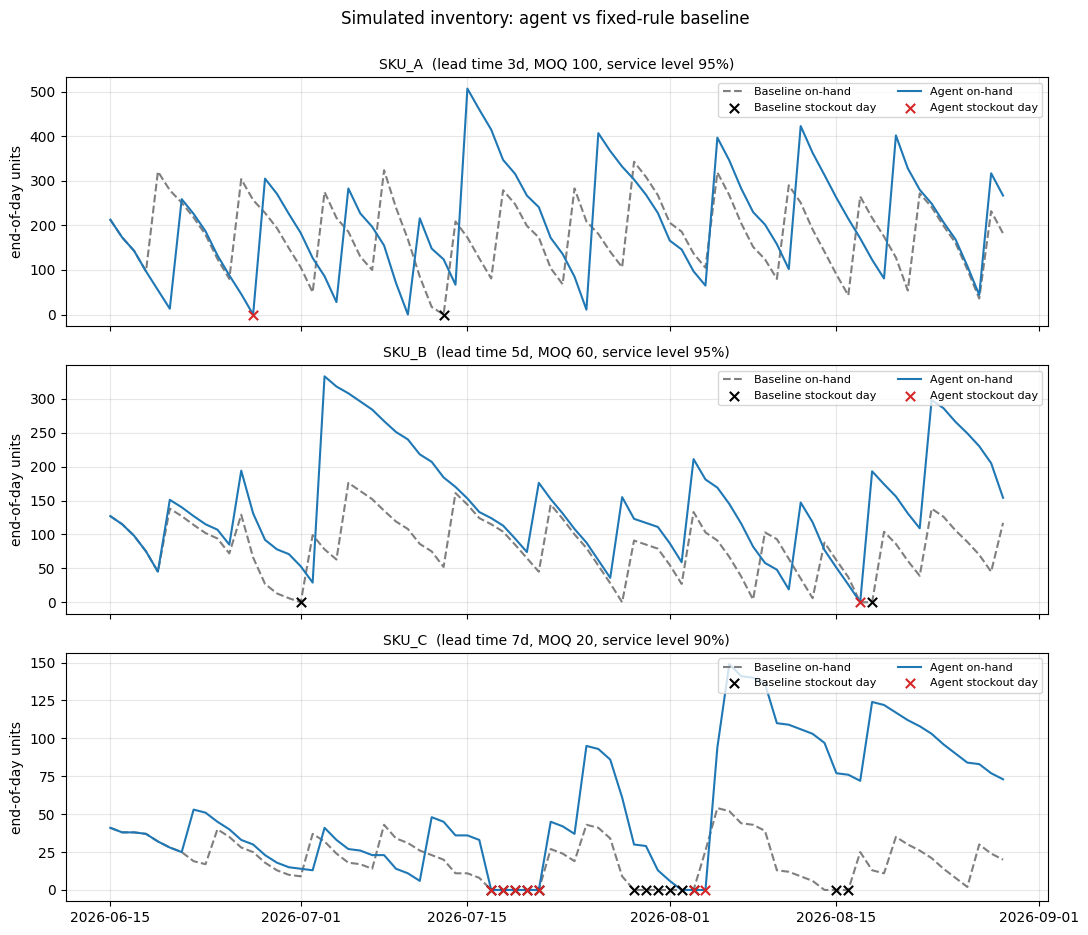

In [11]:
# Inventory trajectories: agent vs baseline, with stockout days marked
fig, axes = plt.subplots(len(PARAMS), 1, figsize=(11, 3.1 * len(PARAMS)), sharex=True)
for ax, sku in zip(np.atleast_1d(axes), PARAMS):
    for log, label, style, color in ((baseline_log, "Baseline", "--", "tab:gray"), (agent_log, "Agent", "-", "tab:blue")):
        g = log[log["sku"] == sku]
        ax.plot(g["date"], g["on_hand_end"], style, color=color, label=f"{label} on-hand")
        hit = g[g["lost"] > 0]
        ax.scatter(hit["date"], hit["on_hand_end"], marker="x", color="tab:red" if label == "Agent" else "black", s=45, zorder=3,
                   label=f"{label} stockout day" if len(hit) else None)
    ax.set_title(f"{sku}  (lead time {PARAMS[sku]['lead_time_days']}d, MOQ {PARAMS[sku]['min_order_qty']}, service level {PARAMS[sku]['service_level']:.0%})", fontsize=10)
    ax.set_ylabel("end-of-day units")
    ax.legend(loc="upper right", fontsize=8, ncol=2)
    ax.grid(alpha=0.3)
fig.suptitle("Simulated inventory: agent vs fixed-rule baseline", y=1.0)
fig.tight_layout()
plt.show()

## 7. Trade offs: how much service does each policy buy per dollar?

A single run can flatter either policy, so we (a) trace each policy's **cost vs fill-rate frontier** by turning its own dial
(the agent's service level; the baseline's buffer days) and (b) repeat the comparison on **30 other simulated demand histories**.

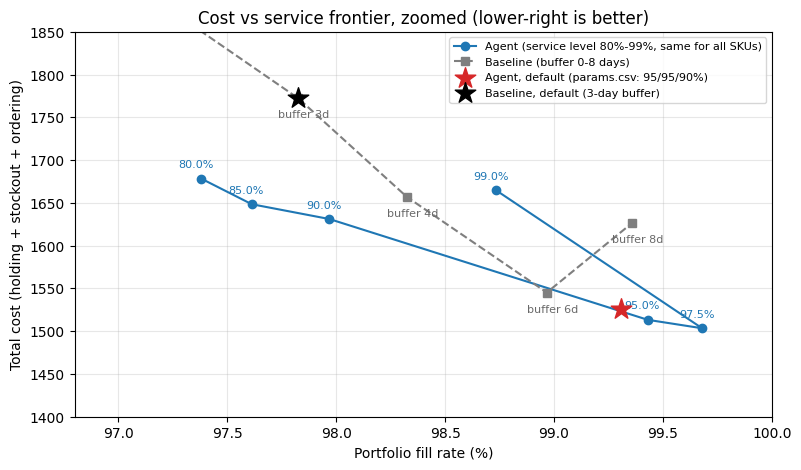

Agent - service level sweep (all other settings unchanged):


,fill_rate,total_cost,holding_cost,stockout_cost
setting,,,,
SL 80.0%,0.974,1678.26,836.76,571.5
SL 85.0%,0.976,1648.39,869.89,508.5
SL 90.0%,0.980,1631.06,952.76,408.3
SL 95.0%,0.994,1513.25,1024.25,219.0
SL 97.5%,0.997,1503.39,1092.19,151.2
SL 99.0%,0.987,1664.44,1184.44,210.0


Baseline - buffer sweep:


,fill_rate,total_cost,holding_cost,stockout_cost
setting,,,,
buffer 0d,0.799,4392.48,276.98,3835.5
buffer 1d,0.894,3146.95,364.15,2452.8
buffer 2d,0.948,2297.78,383.58,1564.2
buffer 3d,0.978,1772.10,511.40,890.7
buffer 4d,0.983,1656.72,572.92,703.8
buffer 6d,0.990,1545.19,714.79,440.4
buffer 8d,0.994,1626.57,924.17,302.4


In [12]:
def portfolio_point(raw, cfg, who):
    """(fill rate, total cost, holding cost, stockout cost) for one policy under one config."""
    run = run_scenario(raw, cfg)
    s = summarise(run[who], run["params"]).loc["ALL"]
    return dict(fill_rate=s["fill_rate"], total_cost=s["total_cost"], holding_cost=s["holding_cost"], stockout_cost=s["stockout_cost"])


agent_default = portfolio_point(RAW, CFG, "agent")        # the configuration used everywhere above (params.csv service levels)
baseline_default = portfolio_point(RAW, CFG, "baseline")  # baseline with buffer_days = CFG.baseline_buffer_days
service_levels = [0.80, 0.85, 0.90, 0.95, 0.975, 0.99]    # note: the sweep sets the SAME service level for every SKU
buffer_days = [0, 1, 2, 3, 4, 6, 8]
agent_curve = pd.DataFrame([dict(setting=f"SL {sl:.1%}", **portfolio_point(RAW, replace(CFG, service_level_override=sl), "agent")) for sl in service_levels])
base_curve = pd.DataFrame([dict(setting=f"buffer {b}d", **portfolio_point(RAW, replace(CFG, baseline_buffer_days=b), "baseline")) for b in buffer_days])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(agent_curve["fill_rate"] * 100, agent_curve["total_cost"], "o-", color="tab:blue", label="Agent (service level 80%-99%, same for all SKUs)")
ax.plot(base_curve["fill_rate"] * 100, base_curve["total_cost"], "s--", color="tab:gray", label="Baseline (buffer 0-8 days)")
for _, r in agent_curve.iterrows():
    ax.annotate(r["setting"].replace("SL ", ""), (r["fill_rate"] * 100, r["total_cost"]), textcoords="offset points", xytext=(-4, 8), fontsize=8, color="tab:blue", ha="center")
for _, r in base_curve.iterrows():
    ax.annotate(r["setting"].replace("buffer ", "buffer "), (r["fill_rate"] * 100, r["total_cost"]), textcoords="offset points", xytext=(4, -14), fontsize=8, color="dimgray", ha="center")
ax.scatter([agent_default["fill_rate"] * 100], [agent_default["total_cost"]], marker="*", s=240, color="tab:red", zorder=4, label="Agent, default (params.csv: 95/95/90%)")
ax.scatter([baseline_default["fill_rate"] * 100], [baseline_default["total_cost"]], marker="*", s=240, color="black", zorder=4, label=f"Baseline, default ({CFG.baseline_buffer_days}-day buffer)")
ax.set_xlim(96.8, 100.0)                       # zoom on the useful region; the baseline's 0-2 day buffers (fill < 95%) are in the table below
ax.set_ylim(1400, 1850)
ax.set_xlabel("Portfolio fill rate (%)")
ax.set_ylabel("Total cost (holding + stockout + ordering)")
ax.set_title("Cost vs service frontier, zoomed (lower-right is better)")
ax.grid(alpha=0.3)
ax.legend(loc="upper right", fontsize=8)
plt.show()

print("Agent - service level sweep (all other settings unchanged):")
display(agent_curve.round(3).set_index("setting"))
print("Baseline - buffer sweep:")
display(base_curve.round(3).set_index("setting"))

In [13]:
def robustness_check(cfg, n_seeds=30):
    """Repeat agent-vs-baseline on n_seeds freshly generated demand histories (same parameters, different random demand)."""
    rows = []
    for seed in range(1, n_seeds + 1):
        raw = validate_data(*generate_data(write=False, seed=seed))
        run = run_scenario(raw, cfg)
        for who in ("baseline", "agent"):
            for sku, r in summarise(run[who], run["params"]).iterrows():
                rows.append(dict(seed=seed, policy=who, sku=sku, total_cost=r["total_cost"], fill_rate=r["fill_rate"], units_short=r["units_short"]))
    return pd.DataFrame(rows)


def robustness_table(robust):
    """Mean fill rate / total cost per SKU and policy, and in how many histories the agent was cheaper."""
    wide = robust.pivot_table(index=["seed", "sku"], columns="policy", values=["fill_rate", "total_cost"])
    rows = []
    for sku in [*PARAMS, "ALL"]:
        w = wide.xs(sku, level="sku")
        cheaper = int((w[("total_cost", "agent")] < w[("total_cost", "baseline")]).sum())
        rows.append({"SKU": sku,
                     "fill: baseline": f"{w[('fill_rate', 'baseline')].mean():.1%}", "fill: agent": f"{w[('fill_rate', 'agent')].mean():.1%}",
                     "cost: baseline": round(w[("total_cost", "baseline")].mean()), "cost: agent": round(w[("total_cost", "agent")].mean()),
                     "cost change": f"{w[('total_cost', 'agent')].mean() / w[('total_cost', 'baseline')].mean() - 1:+.1%}",
                     "agent cheaper in": f"{cheaper}/{len(w)}"})
    return pd.DataFrame(rows).set_index("SKU")


robust = robustness_check(CFG)
print(f"Mean over {robust['seed'].nunique()} other simulated demand histories (same parameters, different random demand):")
display(robustness_table(robust))

Mean over 30 other simulated demand histories (same parameters, different random demand):


,fill: baseline,fill: agent,cost: baseline,cost: agent,cost change,agent cheaper in
SKU,,,,,,
SKU_A,99.8%,98.6%,288,333,+15.4%,7/30
SKU_B,96.5%,96.7%,589,633,+7.4%,11/30
SKU_C,90.7%,95.0%,663,632,-4.6%,16/30
ALL,98.1%,97.8%,1540,1598,+3.7%,13/30


In [14]:
# Auto generated summary so the numbers always match the current run
b, a = base_sum.loc["ALL"], agent_sum.loc["ALL"]
rb = robustness_table(robust).loc["ALL"]
print("RESULT SUMMARY")
print("Shipped dataset (one demand history):")
print(f"  Stockout days : baseline {b['stockout_days']:.0f} -> agent {a['stockout_days']:.0f}   |   units short: {b['units_short']:.0f} -> {a['units_short']:.0f} ({a['units_short'] / b['units_short'] - 1:+.0%})")
print(f"  Fill rate     : {b['fill_rate']:.1%} -> {a['fill_rate']:.1%}  ({(a['fill_rate'] - b['fill_rate']) * 100:+.1f} pp)")
print(f"  Total cost    : {b['total_cost']:,.0f} -> {a['total_cost']:,.0f}  ({a['total_cost'] / b['total_cost'] - 1:+.1%});  "
      f"holding {b['holding_cost']:,.0f} -> {a['holding_cost']:,.0f}, stockout {b['stockout_cost']:,.0f} -> {a['stockout_cost']:,.0f}, ordering {b['order_cost']:,.0f} -> {a['order_cost']:,.0f}")
print(f"  Working capital (avg inventory value): {b['avg_inventory_value']:,.0f} -> {a['avg_inventory_value']:,.0f}")
print(f"Across {robust['seed'].nunique()} other histories: fill rate {rb['fill: baseline']} -> {rb['fill: agent']}, total cost {rb['cost change']} (agent cheaper in {rb['agent cheaper in']}).")

RESULT SUMMARY
Shipped dataset (one demand history):
  Stockout days : baseline 16 -> agent 9   |   units short: 122 -> 39 (-68%)
  Fill rate     : 97.8% -> 99.3%  (+1.5 pp)
  Total cost    : 1,772 -> 1,526  (-13.9%);  holding 511 -> 978, stockout 891 -> 278, ordering 370 -> 270
  Working capital (avg inventory value): 2,708 -> 4,920
Across 30 other histories: fill rate 98.1% -> 97.8%, total cost +3.7% (agent cheaper in 13/30).


### Trade off reflection: inventory vs service

*(Default configuration: seed 42, α = 0.2, order cost 10 per PO.)*

**Service is bought with inventory.** On the shipped data the agent lifts fill rate from 97.8% to 99.3% (units short −68%) but needs about 80% more average inventory value (≈2.7k → ≈4.9k) and nearly double the holding cost. Total cost still falls 13.9% because a missing unit is priced at roughly 70–150× one unit-day of holding. In the sweep, cost is lowest around 95–97.5% service and rises at 99%, where extra safety stock mostly adds holding cost.

**How far to trust it.** That saving is not robust. Over 30 other demand histories the fill rates are similar (baseline 98.1%, agent 97.8%) and the agent is cheaper in only 13 of 30 (+3.7% cost on average). It helps on the volatile, lumpy SKU_C (fill 90.7% → 95.0%, 4.6% cheaper), is roughly a wash on SKU_B, and loses on the stable SKU_A (fill 99.8% → 98.6%, 15% costlier), where a generous fixed buffer is hard to beat. On the frontier plot the policies are close (at ≈99% fill: baseline 6-day buffer ≈1,545 vs agent ≈1,526). So the agent's value is not "always cheaper": it puts buffer where the uncertainty is, adapts to shifts, and explains every order.

**Business choice.** The service level is a policy decision: raise it if stockouts mostly cost customer trust that is hard to price; lower it if cash is tight or items perish.

**Limits.** One short horizon per history; demand treated as uncensored; the EWMA ignores weekly cycles and promotions and still chases bursts (SKU_A ordered 476 units as its Jul 9–12 promo ended; SKU_C's two bulk-demand days pushed it to ~180 units against ~4 a day of normal demand).

## 8. Scaling Note

- **Cloud deployment.** Package the agent as a container and run it as a scheduled job (e.g. nightly via Cloud Scheduler or EventBridge → Cloud Run Job / AWS Batch) after sales close. It reads sales, stock and params from a warehouse or object store, writes recommended POs and the decision log back, and sends orders to the ERP or a buyer for approval.
- **Monitoring.** Log every decision as structured JSON. Alert on rolling fill rate below target (e.g. under a SKU's service level for 3 days), forecast error (RMSE, bias) drifting upward, unusual order sizes or counts, and stockout days per SKU.
- **Reliability.** Retry reads and writes with exponential backoff; make PO submission idempotent (deterministic PO IDs) so retries cannot double-order; validate schema and freshness before each run; if data is missing or stale, reuse the last good forecast, flag the SKU and pause autonomous ordering for it.
- **Cost controls.** Per-SKU inventory cap (`max_cover_days`) and a portfolio working-capital budget (Σ on-hand + on-order × unit cost) tracked daily; orders above a dollar threshold or at a cap need human approval; weekly report of holding, stockout and ordering cost.